## Inhoudsopgave : 

# Inhoudstabel

1. [Imports](#1)
2. [Data Cleaning](#2-data-cleaning)
    - 2.1 [p1](#21-p1)
    - 2.2 [Postal code cleaning](#22-postal-code-cleaning)
3. [Imputing](#3)
4. [Add ages](#4-add-ages)
5. [Regression analysis](#5)

## 1. Imports 


Dit deel is de gegeven code, niet te vergeten:
- 'affordability' is defined as the price per square metre of habitable area


In [28]:
# ---------------------------------------------------------------------------
# 1. Import modules & data
# ---------------------------------------------------------------------------
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from statsmodels.imputation.mice import MICEData
import statsmodels.formula.api as smf
from statsmodels.iolib.summary2 import summary_col

data_immoweb = pd.read_csv("Realo_MBF_datascience_SALE.csv") 


C:\Users\fedra\AppData\Local\Temp\ipykernel_48524\600101958.py:12: DtypeWarning: Columns (21) have mixed types. Specify dtype option on import or set low_memory=False.
  data_immoweb = pd.read_csv("Realo_MBF_datascience_SALE.csv")


In [29]:

# ---------------------------------------------------------------------------
# 2. Data exploration
# ---------------------------------------------------------------------------

"""
In this section we will first convert all variables to their correct datatype
and remove observations that are not from either East-Flanders or Brussels.
"""

# --- Convert variables to their appropriate datatypes ---

# Determine the datatype per variable
dtypes = pd.DataFrame({"dtype": data_immoweb.dtypes.astype(str)})

print("\n" + "=" * 70)
print("DATA TYPE PER VARIABLE (in file order)")
print("=" * 70)
print(dtypes.to_string())

print("\nNumber of variables per data type:")
print(dtypes["dtype"].value_counts().to_string())

# Variables grouped by target datatype
admin_vars = ["addressId", "admin1Id", "admin1", "admin2Id", "admin2",
              "localityId", "locality", "subLocalityId", "subLocality",
              "districtId", "district", "postalCode", "niscode", "region"]
string_vars = ["marker"]
date_vars = ["firstListing", "lastListing", "certificateDate"]
category_vars = ["addressType", "housingType", "secondaryHousingType",
                 "detachment", "way", "heatingType", "floodProneLocation",
                 "buildingCondition"]
bool_vars = ["isPublicSale", "hasGarden", "isNewBuild", "hasSolarPanels",
             "hasSwimmingPool", "hasSingleGlass", "hasDoubleGlass",
             "hasCentralHeating", "hasSolarBoiler"]
int_vars = ["numberOfSides", "numberOfBedrooms", "numberOfBathrooms",
            "numberOfToilets", "numberOfFloors", "floor", "buildYear",
            "renovationYear"]
float_vars = ["lon", "lat", "price", "initialPrice", "habitableArea",
              "terraceArea", "buildingArea", "estimatedArea",
              "estimatedGardenArea", "energyConsumption", "eLevel", "kLevel",
              "distanceToNearestCenter", "busStopDistance",
              "trainStopDistance", "schoolDistance", "mScore",
              "greenCoverage", "cadastralIncome"]

# Step 1: Keep track of missing values before conversion
n_missing_before = data_immoweb.isna().sum()

# Step 2: convert each group
for var in admin_vars + string_vars:
    col = data_immoweb[var]
    # Numeric codes read as floats (e.g. 9000.0) are first made whole numbers,
    # so that the string becomes "9000" and not "9000.0"
    if pd.api.types.is_float_dtype(col):
        col = col.astype("Int64")
    data_immoweb[var] = col.astype("string").str.strip()

for var in date_vars:
    data_immoweb[var] = pd.to_datetime(data_immoweb[var], errors="coerce")

for var in category_vars:
    data_immoweb[var] = data_immoweb[var].astype("string").str.strip().astype("category")

bool_map = {"1": True, "0": False, "1.0": True, "0.0": False,
            "true": True, "false": False, "yes": True, "no": False}
for var in bool_vars:
    data_immoweb[var] = (data_immoweb[var].astype("string").str.strip().str.lower()
                       .map(bool_map).astype("boolean"))

for var in float_vars:
    data_immoweb[var] = pd.to_numeric(data_immoweb[var], errors="coerce").astype("Float64")

for var in int_vars:
    col = pd.to_numeric(data_immoweb[var], errors="coerce")
    non_whole = (col.notna() & (col % 1 != 0)).sum()
    if non_whole > 0:
        # Do not silently round: keep as Float64 and flag it
        print(f"WARNING: {var} has {non_whole} non-whole values; kept as Float64.")
        data_immoweb[var] = col.astype("Float64")
    else:
        data_immoweb[var] = col.astype("Int64")


DATA TYPE PER VARIABLE (in file order)
                           dtype
addressId                  int64
admin1Id                   int64
admin1                    object
admin2Id                   int64
admin2                    object
localityId                 int64
locality                  object
subLocalityId            float64
subLocality               object
districtId               float64
district                  object
postalCode               float64
niscode                   object
region                    object
lon                      float64
lat                      float64
addressType               object
firstListing              object
lastListing               object
housingType               object
secondaryHousingType      object
detachment                object
numberOfSides            float64
price                      int64
initialPrice               int64
way                       object
isPublicSale               int64
habitableArea            float64
ter

## 2. Data cleaning

### 2.1 p1

Dit is de gegeven code, belangrijke punten: 
- meer dan 20% missing data voor een waarde -> parameter wordt verwijdert 


DATATYPE CONVERSION
No values were lost in the conversion.

Datatypes after conversion:
addressId                          string
admin1Id                           string
admin1                             string
admin2Id                           string
admin2                             string
localityId                         string
locality                           string
subLocalityId                      string
subLocality                        string
districtId                         string
district                           string
postalCode                         string
niscode                            string
region                             string
lon                               Float64
lat                               Float64
addressType                      category
firstListing               datetime64[ns]
lastListing                datetime64[ns]
housingType                      category
secondaryHousingType             category
detachment                   

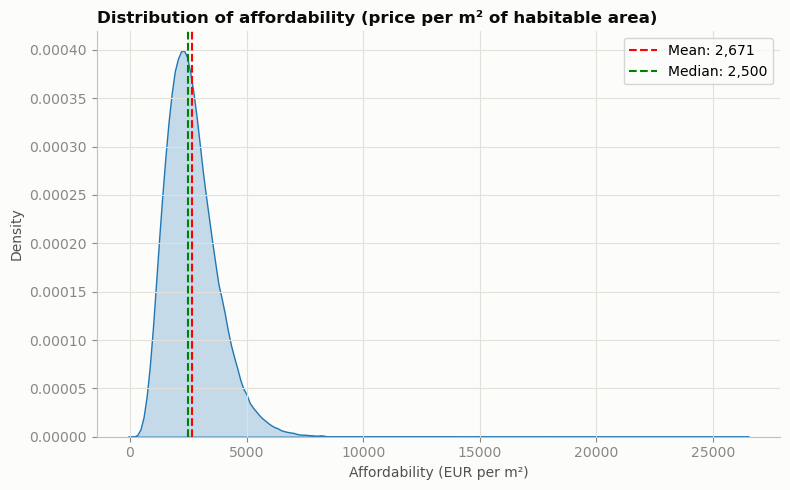

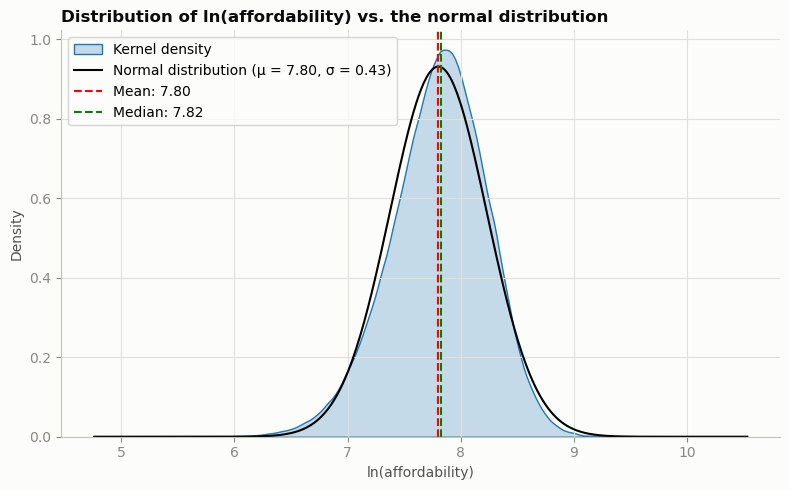

In [30]:
# Step 3: check that the conversion did not create new missing values
# (a value that could not be converted, e.g. text in a numeric column, becomes <NA>)
n_missing_after = data_immoweb.isna().sum()
new_missing = (n_missing_after - n_missing_before)
new_missing = new_missing[new_missing > 0]

print("\n" + "=" * 70)
print("DATATYPE CONVERSION")
print("=" * 70)
if new_missing.empty:
    print("No values were lost in the conversion.")
else:
    print("Values that could not be converted and are now missing:")
    print(new_missing.to_string())

print("\nDatatypes after conversion:")
print(data_immoweb.dtypes.astype(str).to_string())

dtypes_after_conversion = pd.DataFrame({"dtype": data_immoweb.dtypes.astype(str)})
print("\nNumber of variables per data type:")
print(dtypes_after_conversion["dtype"].value_counts().to_string())

# --- Observations per region, split by housing type ---

# Number of observations per unique value of admin1 and admin2, split by
# housingType (i.e. APARTMENT vs HOUSE).
for region_var in ["admin1", "admin2"]:
    counts = pd.crosstab(
        data_immoweb[region_var].astype(object),
        data_immoweb["housingType"].astype(object),
        margins=True, margins_name="Total",
    )
    print("\n" + "=" * 70)
    print(f"NUMBER OF OBSERVATIONS PER {region_var.upper()} AND HOUSING TYPE")
    print("=" * 70)
    print(counts.to_string())

# We remove these as Brugge is neither part of Oost-Vlaanderen nor Brussels 
data_immoweb = data_immoweb[data_immoweb["admin2"] != "Brugge"]

# ---------------------------------------------------------------------------
# 3. A first look at the missing values and defining "affordability"
# ---------------------------------------------------------------------------

"""
In this section we take a first look at the missing observations and define our
dependent variable. First, we determine the number of missing observations per
variable and remove all variables with more than 20% missing observations.
Next, we remove the variables that are not needed for the further analysis.
Lastly, we define the dependent variable 'affordability' (price per square 
metre of habitable area), remove the observations for which it is missing, plot its
distribution, and do the same for its log, 'ln(affordability)'.
"""

# --- Determine the number of missing observations per variable ---

# Calculate the number of missing values per variable
missing = pd.DataFrame({
    "n_missing": data_immoweb.isna().sum(),
    "pct_missing": (data_immoweb.isna().mean() * 100).round(2),
}).sort_values("pct_missing", ascending=False)

print("\n" + "=" * 70)
print("MISSING VALUES PER VARIABLE (sorted, highest first)")
print("=" * 70)
print(missing.to_string())

print(f"\nVariables with no missing values:   {(missing['n_missing'] == 0).sum()}")
print(f"Variables with some missing values: {(missing['n_missing'] > 0).sum()}")
print(f"Variables completely empty (100%):  {(missing['pct_missing'] == 100).sum()}")

# --- Remove variables with more than 20% missing observations ---

# Maximum share of missing observations (in %) a variable may have to be kept.
max_pct_missing = 20

pct_missing = data_immoweb.isna().mean() * 100
vars_to_remove = pct_missing[pct_missing > max_pct_missing].index.tolist()

print("\n" + "=" * 70)
print(f"VARIABLES REMOVED (MORE THAN {max_pct_missing}% MISSING)")
print("=" * 70)
print(missing.loc[vars_to_remove].to_string())
print(f"\nNumber of variables removed: {len(vars_to_remove)}")

data_immoweb_cleaned = data_immoweb.drop(columns=vars_to_remove)

# --- Overview of the remaining variables ---

print("\n" + "=" * 70)
print(f"REMAINING VARIABLES ({data_immoweb.shape[1]} variables, "
      f"{data_immoweb.shape[0]} observations)")
print("=" * 70)
print(data_immoweb_cleaned.columns.tolist())

# Number (and share) of missing observations per remaining variable, in file order
missing_remaining = pd.DataFrame({
    "n_missing": data_immoweb_cleaned.isna().sum(),
    "pct_missing": (data_immoweb_cleaned.isna().mean() * 100).round(2),
})

print("\n" + "=" * 70)
print("MISSING VALUES PER REMAINING VARIABLE")
print("=" * 70)
print(missing_remaining.to_string())
print(f"\nRemaining variables with no missing values:   {(missing_remaining['n_missing'] == 0).sum()}")
print(f"Remaining variables with some missing values: {(missing_remaining['n_missing'] > 0).sum()}")


# --- Remove variables that are not needed for the further analysis ---

# 1) Location IDs: these are only internal identifiers (of the address and of
#    the administrative areas) and carry no information of their own for the
#    analysis.
id_vars = ["addressId", "admin1Id", "admin2Id", "localityId", "subLocalityId",
           "districtId"]

# 2) Location variables below the 'admin2' level: we will work with the data at
#    the granularity of 'admin2' (arrondissement), so variables that indicate the
#    location at an even more granular level are redundant.
granular_location_vars = ["district","niscode"] # CHANGE was earlier -> ["subLocality", "district", "postalCode", "niscode"] 

#CHANGE : we however WILL keep the granular locality variables partly to understand the differences between municipalities within the same arrondissements 

# 3) 'region': this variable only takes on the values "Flanders" and
#    "Bruxelles", so it is redundant because this information is already
#    covered by 'admin1'.
region_vars = ["region"]

# 4) Distances to the nearest centre, bus stop, train stop and school: these
#    are redundant because 'mScore' already aggregates this information.
#    Moreover, the bus stop, train stop and school distances contain many more
#    missing observations than 'mScore'.
distance_vars = ["distanceToNearestCenter", "busStopDistance",
                 "trainStopDistance", "schoolDistance"]

# 5) 'way': this variable only takes on one value ("SALE"), so it carries no
#    information.
constant_vars = ["way"]

# 6) 'marker': this variable contains the coordinates of the dwelling, so it is
#    redundant because this information is already covered by 'lon' and 'lat'.
coordinate_vars = ["marker"]

# 7) 'secondaryHousingType': this variable is too granular, as there are almost
#    no observations for certain categories. We use 'housingType' (house vs
#    apartment) instead.
housing_type_vars = ["secondaryHousingType"]

# 8) 'addressType': this variable "specifies the category of the listed
#    address", which is not relevant for our purpose.
address_type_vars = ["addressType"]

redundant_vars = (id_vars + region_vars + distance_vars +granular_location_vars           
                  + constant_vars + coordinate_vars + housing_type_vars
                  + address_type_vars)

# errors="ignore": some of these variables may already have been removed above
# because they had more than 20% missing observations
data_immoweb_cleaned = data_immoweb_cleaned.drop(columns=redundant_vars,
                                                 errors="ignore")

print("\n" + "=" * 70)
print(f"VARIABLES KEPT FOR THE ANALYSIS ({data_immoweb_cleaned.shape[1]} variables, "
      f"{data_immoweb_cleaned.shape[0]} observations)")
print("=" * 70)
print(data_immoweb_cleaned.columns.tolist())


# --- Define the dependent variable 'affordability' ---

# 'affordability' is defined as the price per square metre of habitable area
data_immoweb_cleaned["affordability"] = (data_immoweb_cleaned["price"]
                                         / data_immoweb_cleaned["habitableArea"])

# Remove all rows with a missing value for 'affordability' (i.e. a missing
# 'price' or 'habitableArea'). We do this because 'affordability' will be the
# dependent variable in our regressions, and it does not make sense to impute
# the dependent variable.
n_before = len(data_immoweb_cleaned)
data_immoweb_cleaned = data_immoweb_cleaned.dropna(subset=["affordability"])
n_after = len(data_immoweb_cleaned)

print("\n" + "=" * 70)
print("REMOVE OBSERVATIONS WITH MISSING 'affordability'")
print("=" * 70)
print(f"Observations before:  {n_before}")
print(f"Observations removed: {n_before - n_after} "
      f"({(n_before - n_after) / n_before * 100:.2f}%)")
print(f"Observations after:   {n_after}")

# Kernel density plot of 'affordability'. First convert to a regular float
# Series (seaborn does not always handle the nullable Float64 datatype well)
affordability = data_immoweb_cleaned["affordability"].astype(float)

mean_affordability = affordability.mean()
median_affordability = affordability.median()

fig, ax = plt.subplots(figsize=(8, 5))
sns.kdeplot(x=affordability, ax=ax, fill=True)

# Add vertical lines for the mean and median
ax.axvline(mean_affordability, color="red", linestyle="--",
           label=f"Mean: {mean_affordability:,.0f}")
ax.axvline(median_affordability, color="green", linestyle="--",
           label=f"Median: {median_affordability:,.0f}")

ax.set_title("Distribution of affordability (price per m\u00b2 of habitable area)")
ax.set_xlabel("Affordability (EUR per m\u00b2)")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()

# Take the log of 'affordability'
data_immoweb_cleaned["ln(affordability)"] = np.log(data_immoweb_cleaned["affordability"])

# Kernel density plot of 'ln(affordability)'
ln_affordability = data_immoweb_cleaned["ln(affordability)"].astype(float)

mean_ln_affordability = ln_affordability.mean()
median_ln_affordability = ln_affordability.median()

std_ln_affordability = ln_affordability.std()

fig, ax = plt.subplots(figsize=(8, 5))
sns.kdeplot(x=ln_affordability, ax=ax, fill=True, label="Kernel density")

# Overlay a normal distribution with the same mean and standard deviation as
# 'ln(affordability)', to see how close the variable is to being normally
# distributed
x_values = np.linspace(*ax.get_xlim(), 500)
normal_density = (np.exp(-0.5 * ((x_values - mean_ln_affordability)
                                  / std_ln_affordability) ** 2)
                  / (std_ln_affordability * np.sqrt(2 * np.pi)))
ax.plot(x_values, normal_density, color="black", linewidth=1.5,
        label=f"Normal distribution (\u03bc = {mean_ln_affordability:.2f}, "
              f"\u03c3 = {std_ln_affordability:.2f})")

# Add vertical lines for the mean and median
ax.axvline(mean_ln_affordability, color="red", linestyle="--",
           label=f"Mean: {mean_ln_affordability:.2f}")
ax.axvline(median_ln_affordability, color="green", linestyle="--",
           label=f"Median: {median_ln_affordability:.2f}")

ax.set_title("Distribution of ln(affordability) vs. the normal distribution")
ax.set_xlabel("ln(affordability)")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()


In [31]:
data_immoweb_BG = data_immoweb_cleaned[data_immoweb_cleaned['admin2'].isin(['Bruxelles-Capitale', 'Gent'])].copy()

counts = data_immoweb_BG['locality'].value_counts()
keep = counts[counts >= 50].index
removed = counts[counts < 50].index
print("Rows before:", len(data_immoweb_BG))
data_immoweb_BG = data_immoweb_BG[data_immoweb_BG['locality'].isin(keep)].copy()
print("Rows after:", len(data_immoweb_BG))
print("Localities removed:", (counts < 50).sum(), removed)
# we removed localities with less than 50 observations, as they are too few to be useful for the analysis.

Rows before: 281956
Rows after: 281953
Localities removed: 2 Index(['Beersel', 'Lokeren'], dtype='string', name='locality')


### 2.2 Postal code cleaning

In [32]:
no_postal_code = data_immoweb_BG[data_immoweb_BG['postalCode'].isnull()]
print(no_postal_code[no_postal_code['locality'].isnull()])
#nothing printed, so no missing locality for the missing postal codes. This means that we can use the locality to impute the missing postal codes.
print(no_postal_code[no_postal_code['subLocality'].isnull()]['locality'])
#sometimes subLocality is missing, but we can use the locality to impute the missing postal codes.


Empty DataFrame
Columns: [admin1, admin2, locality, subLocality, postalCode, lon, lat, firstListing, lastListing, housingType, price, initialPrice, isPublicSale, habitableArea, estimatedArea, hasGarden, isNewBuild, buildYear, heatingType, floodProneLocation, numberOfBedrooms, numberOfBathrooms, mScore, greenCoverage, hasSolarPanels, affordability, ln(affordability)]
Index: []

[0 rows x 27 columns]
0          Woluwe-Saint-Lambert
3                    Schaerbeek
5                         Jette
16                   Anderlecht
17          Woluwe-Saint-Pierre
                  ...          
540096    Berchem-Sainte-Agathe
540097    Berchem-Sainte-Agathe
540098    Berchem-Sainte-Agathe
540100                   Forest
540106    Saint-Josse-ten-Noode
Name: locality, Length: 2380, dtype: string


In [33]:
# 1. Split into the two groups
complete = data_immoweb_BG[data_immoweb_BG['postalCode'].notna()]
missing_rows = data_immoweb_BG['postalCode'].isna()

print("Missing before:", missing_rows.sum())

# 2. Most common postal code per subLocality in the complete group
most_common = (
    complete.dropna(subset=['subLocality'])
            .groupby('subLocality')['postalCode']
            .agg(lambda s: s.value_counts().idxmax())
)

# 3. Fill the missing rows directly in the original DataFrame
data_immoweb_BG.loc[missing_rows, 'postalCode'] = (
    data_immoweb_BG.loc[missing_rows, 'subLocality'].map(most_common)
)

print("Rows in data:", len(data_immoweb_BG))
print("Still missing postal code:", data_immoweb_BG['postalCode'].isna().sum())

Missing before: 2683
Rows in data: 281953
Still missing postal code: 2380


In [34]:
complete = data_immoweb_BG[data_immoweb_BG['postalCode'].notna()]
missing = data_immoweb_BG['postalCode'].isna()
print("Missing before:", missing.sum())

# Most common postal code per locality in the complete group
mode_loc = (
    complete.groupby('locality')['postalCode']
            .agg(lambda s: s.value_counts().idxmax())
)

# Fill the missing rows directly in data_immoweb_BG
data_immoweb_BG.loc[missing, 'postalCode'] = (
    data_immoweb_BG.loc[missing, 'locality'].map(mode_loc)
)

print("Missing after:", data_immoweb_BG['postalCode'].isna().sum())

Missing before: 2380
Missing after: 0


## Imputing missing values for mScore, greenCoverage and cadastralIncome using MICE (Multiple Imputation by Chained Equations)lue

from now one we use : data_immoweb_BG as a dataframe


Number of observations per value of 'numberOfBedrooms' (7 unique values, 10427 missing):
numberOfBedrooms
1    43068
2    96544
3    80474
4    34239
5    11373
6     4577
7     1251


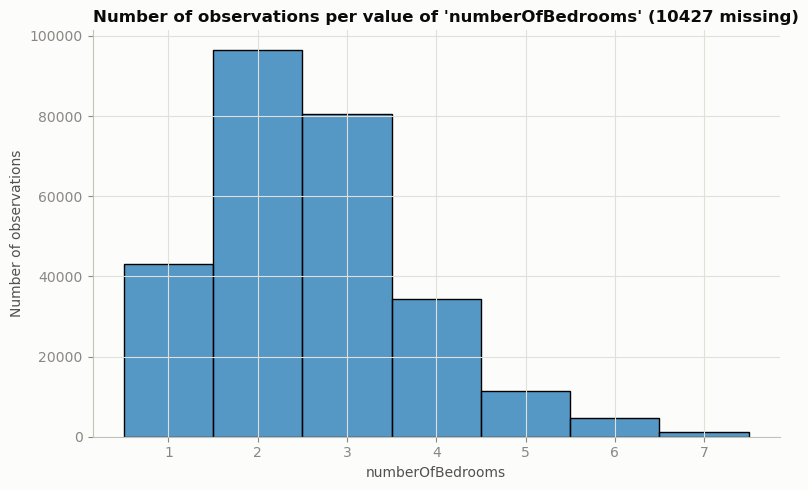


Number of observations per value of 'numberOfBathrooms' (6 unique values, 30431 missing):
numberOfBathrooms
0      4170
1    153755
2     69097
3     15093
4      8377
5      1030


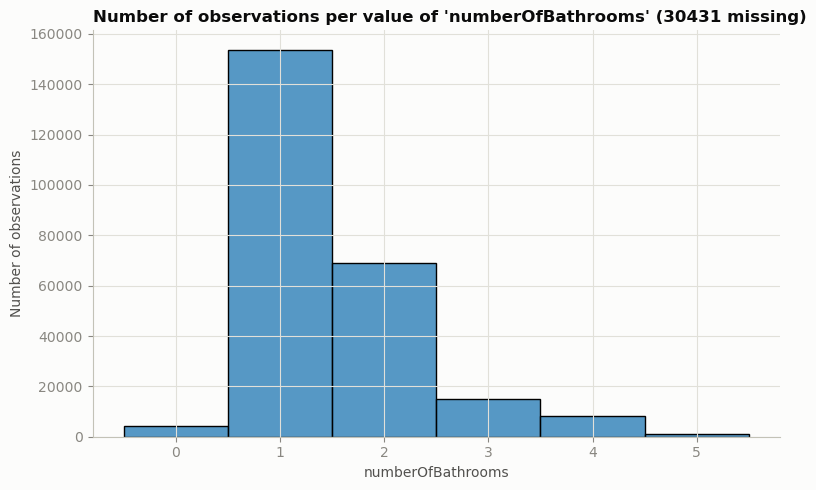


Number of observations per value of 'buildYear' (258 unique values, 46750 missing):
buildYear
1700       9
1706       1
1707       6
1720       1
1723       1
1726      10
1734       6
1735       1
1743       2
1750      13
1752       1
1753       7
1754       2
1755       2
1756       3
1758       1
1759       4
1760       7
1762       1
1764       1
1767       1
1768       4
1769      15
1770       5
1771       1
1773       2
1774       5
1775       3
1776       3
1777       3
1778      12
1779       3
1780       4
1783       3
1784       6
1785       4
1786       3
1788       3
1789       2
1790       6
1792       8
1794       1
1799       1
1800      91
1804       3
1807       1
1809       2
1810       3
1812       1
1813       1
1815       5
1819       2
1820      10
1821       1
1822       8
1824      10
1825      19
1828       1
1829       4
1830      32
1831       5
1832       8
1833       2
1834       6
1835       2
1836       3
1837       3
1838       1
1839       2
1840    

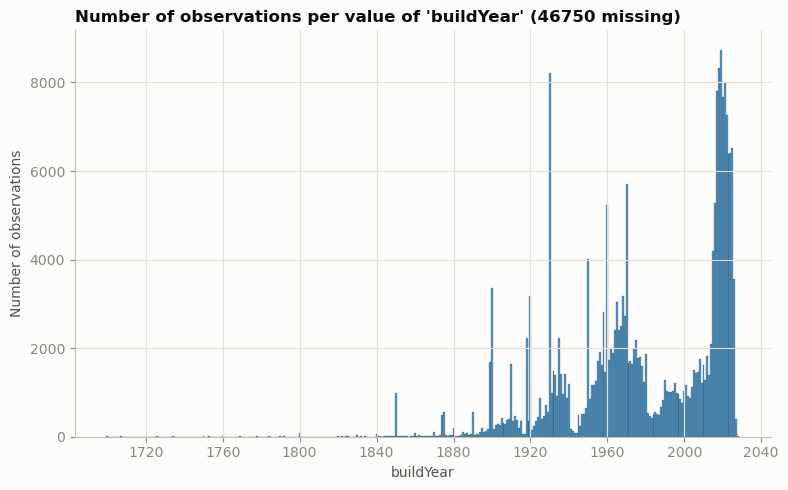


CATEGORIES OF 'numberOfBedrooms'
numberOfBedrooms
1      43068
2      96544
3      80474
3+     51440
NaN    10427

CATEGORIES OF 'numberOfBathrooms'
numberOfBathrooms
1      157925
2       69097
2+      24500
NaN     30431

CATEGORIES OF 'buildYear'
buildYear
<1980    117050
>1980     31024
>2010     87129
NaN       46750

CATEGORIES OF 'heatingType'
heatingType
GAS           186087
HEAT_PUMP      21899
FUEL_OIL       17251
ELECTRICAL     12358
OTHER           3545
NaN            40813

MISSING VALUES PER REMAINING VARIABLE (27 variables, 281953 observations)
                    n_missing  pct_missing
estimatedArea           62947        22.33
buildYear               46750        16.58
floodProneLocation      43630        15.47
heatingType             40813        14.48
numberOfBathrooms       30431        10.79
numberOfBedrooms        10427         3.70
lastListing              6434         2.28
mScore                   4916         1.74
subLocality              4745         1.68
ad

In [35]:



# ---------------------------------------------------------------------------
# 4. Determining categories
# ---------------------------------------------------------------------------

"""
In the next step we will have to impute the missing observations. This is
easier to do if we first group the values of a variable into a smaller number
of categories from which the imputing algorithm can choose. We will do so for a
number of variables which can be defined as categorical variables with a large
number of unique values, and for which using the full spectrum of values has
little added value.
"""

# --- Number of observations per category ---

# Candidate variables: count variables with many unique values (e.g. the number
# of bedrooms) and the construction year.
candidate_vars = ["numberOfBedrooms", "numberOfBathrooms", "buildYear"]

for var in candidate_vars:
    # Convert to a regular float Series and drop the missing values for the plot
    values = data_immoweb_BG[var].astype(float).dropna()
    n_missing = data_immoweb_BG[var].isna().sum()

    # Number of observations per unique value (also printed, so that categories
    # with very few observations are easy to spot)
    print(f"\nNumber of observations per value of '{var}' "
          f"({values.nunique()} unique values, {n_missing} missing):")
    print(data_immoweb_BG[var].value_counts().sort_index().to_string())

    # Histogram with one bar per unique value (discrete=True)
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.histplot(x=values, discrete=True, ax=ax)
    ax.set_title(f"Number of observations per value of '{var}' "
                 f"({n_missing} missing)")
    ax.set_xlabel(var)
    ax.set_ylabel("Number of observations")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))  # whole numbers only
    plt.tight_layout()
    plt.show()

# --- Create the categories ---

# For every variable we define the bin edges and the name of each category.
# pd.cut() puts a value in a bin if: lower edge < value <= upper edge.
# Missing values remain missing, so that they can be imputed in the next step.
category_definitions = {
    # numberOfBedrooms: 1, 2, 3 and more than 3 bedrooms ("3+").
    # Note: dwellings with 0 bedrooms (e.g. studios) are counted towards "1".
    "numberOfBedrooms": {"bins": [-np.inf, 1, 2, 3, np.inf],
                         "labels": ["1", "2", "3", "3+"]},

    # numberOfBathrooms: 1, 2 and more than 2 bathrooms ("2+").
    # Note: 0 bathrooms is counted towards "1", as we consider a dwelling
    # without a bathroom to be a data error.
    "numberOfBathrooms": {"bins": [-np.inf, 1, 2, np.inf],
                          "labels": ["1", "2", "2+"]},

    # buildYear: built before 1980 ("<1980"), between 1980 and 2010 (">1980")
    # and after 2010 (">2010"). The years 1980 and 2010 themselves are both
    # counted towards ">1980".
    "buildYear": {"bins": [-np.inf, 1979, 2010, np.inf],
                  "labels": ["<1980", ">1980", ">2010"]},
}

for var, definition in category_definitions.items():
    # Replace the original values by their category (an ordered categorical)
    data_immoweb_BG[var] = pd.cut(data_immoweb_BG[var].astype(float),
                                  bins=definition["bins"],
                                  labels=definition["labels"])

    print("\n" + "=" * 70)
    print(f"CATEGORIES OF '{var}'")
    print("=" * 70)
    print(data_immoweb_BG[var].value_counts(dropna=False, sort=False).to_string())

# --- Group the categories of 'heatingType' ---

# 'heatingType' has many categories, several of which have very few
# observations (and some are numeric codes, e.g. "30", whose meaning is
# unknown). We keep the four most common heating types and group all other
# observed values into "OTHER". Missing values remain missing, so that they can
# be imputed in the next step.
main_heating_types = ["GAS", "HEAT_PUMP", "FUEL_OIL", "ELECTRICAL"]
heating = data_immoweb_BG["heatingType"].astype(object)
heating = heating.where(heating.isin(main_heating_types) | heating.isna(), "OTHER")
data_immoweb_BG["heatingType"] = pd.Categorical(
    heating, categories=main_heating_types + ["OTHER"])

print("\n" + "=" * 70)
print("CATEGORIES OF 'heatingType'")
print("=" * 70)
print(data_immoweb_BG["heatingType"].value_counts(dropna=False, sort=False).to_string())


# --- Missing values per remaining variable ---

# Number (and share) of missing observations per variable that is left in the
# dataset, sorted from highest to lowest. These are the variables that will
# have to be imputed in the next step.
missing_final = pd.DataFrame({
    "n_missing": data_immoweb_BG.isna().sum(),
    "pct_missing": (data_immoweb_BG.isna().mean() * 100).round(2),
}).sort_values("pct_missing", ascending=False)

print("\n" + "=" * 70)
print(f"MISSING VALUES PER REMAINING VARIABLE ({data_immoweb_BG.shape[1]} "
      f"variables, {data_immoweb_BG.shape[0]} observations)")
print("=" * 70)
print(missing_final.to_string())
print(f"\nVariables with no missing values:   {(missing_final['n_missing'] == 0).sum()}")
print(f"Variables with some missing values: {(missing_final['n_missing'] > 0).sum()}")


## 3. Imputing 

In [36]:
import statsmodels
print(statsmodels.__version__)
from statsmodels.imputation.mice import MICEData
help(MICEData.__init__)

0.15.0
Help on function __init__ in module statsmodels.imputation.mice:

__init__(self, data, perturbation_method='gaussian', k_pmm=20, history_callback=None, rng=None)
    Initialize self.  See help(type(self)) for accurate signature.



In [37]:

# 5. Imputing the missing values
# ---------------------------------------------------------------------------

"""
In this section we impute the remaining missing values using MICE (Multiple
Imputation by Chained Equations; van Buuren & Groothuis-Oudshoorn, 2011),
combined with predictive mean matching (PMM).

MICE imputes the variables one by one: each variable with missing values is
regressed on the other variables. Because these other variables contain missing
values as well (which are first filled in with the observed value closest to
the mean), this is repeated over several rounds, each time using the latest
imputations, until the imputed values stabilise.

PMM determines which value is filled in. The regression gives a predicted value
for every dwelling, also for the dwellings where the value is observed. For a
dwelling with a missing value, we look for the 20 dwellings with an observed
value whose prediction is closest to its own prediction, randomly pick one of
these 20 'donors' and fill in the donor's observed value. As a result:
 - only values that actually occur in the data are imputed (e.g. only existing
   categories, no negative areas). This is also why we created categories in
   section 4: the imputer chooses from a small number of observed categories;
 - the imputed values keep the natural variation in the data, instead of all
   lying on the regression line.

We use the MICE implementation of statsmodels (MICEData). Strictly speaking,
MICE creates several ('multiple') imputed datasets and combines the regression
results over these datasets. To keep things simple, we create a single imputed
dataset.

Two variables are not imputed with MICE: 'lastListing' is set to a fixed date
(in both datasets) and 'heatingType' is set to its most common value (see
below).
"""

# --- 'lastListing': set missing values to the extraction date ---

# The data was extracted on 10/08/2026. A missing 'lastListing' means that the
# dwelling was still listed on the day the data was extracted, so we set its
# last listing date to the extraction date rather than imputing it. As this is
# a rule rather than an imputation, we apply it before making the copy below,
# so that it holds for both 'data_immoweb_cleaned' and
# 'data_immoweb_cleaned_imputed'. 

#CHANGE we use data_immoweb_BG instead of data_immoweb_cleaned, as we are only interested in the Brussels and Gent data for the analysis.

extraction_date = pd.Timestamp("2026-08-10")

n_missing_lastListing = data_immoweb_BG["lastListing"].isna().sum()
data_immoweb_BG["lastListing"] = data_immoweb_BG["lastListing"].fillna(extraction_date)
print(f"\n'lastListing': {n_missing_lastListing} missing values set to "
      f"{extraction_date:%d/%m/%Y}")

# --- Create a separate dataset for the imputations ---

# All imputations are done on a copy of the dataset, 'data_immoweb_cleaned_imputed'.
# 'data_immoweb_cleaned' keeps its missing values, so that we can later compare
# the regression results with and without imputation.
data_immoweb_BG_imputed = data_immoweb_BG.copy()

# --- 'heatingType': set missing values to the most common value ---

# 'heatingType' has no natural order (e.g. gas is not 'more' or 'less' than
# electrical), so it cannot be imputed with the regressions used by MICE.
# Instead, we fill in the most common heating type among dwellings in the same
# 'admin2' and of the same 'housingType'. This is simple and transparent, but
# note that it understates the variation in heating types.
n_missing_heating = data_immoweb_BG_imputed["heatingType"].isna().sum()
most_common_heating = (data_immoweb_BG_imputed
                       .groupby(["admin2", "housingType"], observed=True)["heatingType"]
                       .transform(lambda x: x.mode().iloc[0]))
data_immoweb_BG_imputed["heatingType"] = data_immoweb_BG_imputed["heatingType"].fillna(most_common_heating)
print(f"'heatingType': {n_missing_heating} missing values set to the most common "
      f"value per admin2 and housingType")

# --- 'floodProneLocation': put the categories in a logical order ---

# The regressions use category numbers (see below), so the order of the
# categories has to be meaningful: no < possible < yes.
data_immoweb_BG_imputed["floodProneLocation"] = (data_immoweb_BG_imputed["floodProneLocation"]
                                              .cat.set_categories(["no", "possible", "yes"],
                                                                  ordered=True))

# --- Prepare the data for the imputer ---

# Variables to impute:
#  - continuous variables, used as they are;
#  - categorical variables, which are replaced by their category number
#    (0, 1, 2, ...). Their categories are ordered (e.g. "1" < "2" < "3" < "3+"
#    bedrooms), so the category number can be used in a regression.
continuous_vars = ["estimatedArea", "mScore"]
category_vars = ["buildYear", "floodProneLocation", "numberOfBathrooms",
                 "numberOfBedrooms"]

# Predictors without missing values, which help to predict the variables above:
#  - 'ln(affordability)', our dependent variable. It is not imputed (it has no
#    missing values), but leaving it out would weaken the relation between the
#    imputed variables and the dependent variable;
#  - characteristics of the dwelling and its location (booleans become 1/0);
#  - the year of 'firstListing', and dummies for 'admin2', 'housingType' and
#    'heatingType' (e.g. dwellings in Brussels are smaller, older, ...).
# Left out:
#  - 'price', 'initialPrice' and 'affordability', as they contain largely the
#    same information as 'ln(affordability)';
#  - 'habitableArea', as it is used to calculate 'ln(affordability)';
#  - 'lat' and 'lon', as these coordinates are too granular;
#  - 'admin1', as it is covered by 'admin2', and 'locality', as it is too
#    granular.
predictor_vars = ["ln(affordability)", "greenCoverage", "hasGarden",
                  "hasSolarPanels", "isNewBuild", "isPublicSale"]

data_for_imputer = data_immoweb_BG_imputed[continuous_vars + predictor_vars].astype(float)
for col in category_vars:
    # .cat.codes gives -1 for a missing value; turn this back into a missing value
    data_for_imputer[col] = data_immoweb_BG_imputed[col].cat.codes.replace(-1, np.nan).astype(float)
data_for_imputer["firstListingYear"] = data_immoweb_BG_imputed["firstListing"].dt.year.astype(float)
data_for_imputer = data_for_imputer.join(
    pd.get_dummies(data_immoweb_BG_imputed[["admin2", "housingType", "heatingType"]].astype(object),
                   drop_first=True, dtype=float))

# statsmodels writes the regressions as formulas internally, which do not accept
# names such as 'ln(affordability)' or 'admin2_Sint-Niklaas'. We therefore
# temporarily rename the columns to x0, x1, x2, ...
original_names = data_for_imputer.columns
data_for_imputer.columns = [f"x{i}" for i in range(len(original_names))]

# --- Run the imputer ---

# k_pmm=20: the number of donors from which the imputed value is drawn.
# rng=42: fixes the seed of the random draws, so that every run gives the same
# imputations (requires statsmodels 0.15 or later).
# update_all(n_iter=10): 10 rounds over all variables with missing values.
imputer = MICEData(data_for_imputer, k_pmm=20, rng=42)
imputer.update_all(n_iter=10)

imputed = imputer.data
imputed.columns = original_names
imputed.index = data_immoweb_BG_imputed.index

# --- Put the imputed values back into the dataset ---

# Observed values are not changed by the imputer; only the missing values are
# filled in.
was_missing = data_immoweb_BG_imputed[continuous_vars + category_vars].isna()

for col in continuous_vars:
    data_immoweb_BG_imputed[col] = imputed[col].astype("Float64")
for col in category_vars:
    # Convert the category numbers back to the categories
    data_immoweb_BG_imputed[col] = pd.Categorical.from_codes(
        imputed[col].astype(int),
        categories=data_immoweb_BG_imputed[col].cat.categories, ordered=True)

print("\n" + "=" * 70)
print("NUMBER OF IMPUTED VALUES PER VARIABLE")
print("=" * 70)
print(was_missing.sum().to_string())

# Check: compare the distribution of the observed and the imputed values. Large
# differences are not necessarily wrong (the dwellings with missing values can
# differ from the others), but they are worth a closer look.
for col in category_vars:
    print("\n" + "=" * 70)
    print(f"OBSERVED VS IMPUTED VALUES OF '{col}' (share in %)")
    print("=" * 70)
    print(pd.DataFrame({
        "observed": data_immoweb_BG_imputed.loc[~was_missing[col], col].value_counts(normalize=True, sort=False) * 100,
        "imputed": data_immoweb_BG_imputed.loc[was_missing[col], col].value_counts(normalize=True, sort=False) * 100,
    }).round(1).to_string())

for col in continuous_vars:
    print("\n" + "=" * 70)
    print(f"OBSERVED VS IMPUTED VALUES OF '{col}'")
    print("=" * 70)
    print(pd.DataFrame({
        "observed": data_immoweb_BG_imputed.loc[~was_missing[col], col].astype(float).describe(),
        "imputed": data_immoweb_BG_imputed.loc[was_missing[col], col].astype(float).describe(),
    }).T.round(2).to_string())

print("\n" + "=" * 70)
print("MISSING VALUES AFTER IMPUTATION")
print("=" * 70)
print(f"Total number of missing values left: {data_immoweb_BG_imputed.isna().sum().sum()}")




'lastListing': 6434 missing values set to 10/08/2026
'heatingType': 40813 missing values set to the most common value per admin2 and housingType

NUMBER OF IMPUTED VALUES PER VARIABLE
estimatedArea         62947
mScore                 4916
buildYear             46750
floodProneLocation    43630
numberOfBathrooms     30431
numberOfBedrooms      10427

OBSERVED VS IMPUTED VALUES OF 'buildYear' (share in %)
           observed  imputed
buildYear                   
<1980          49.8     78.1
>1980          13.2     16.9
>2010          37.0      4.9

OBSERVED VS IMPUTED VALUES OF 'floodProneLocation' (share in %)
                    observed  imputed
floodProneLocation                   
no                      70.7     71.9
possible                23.6     23.8
yes                      5.7      4.3

OBSERVED VS IMPUTED VALUES OF 'numberOfBathrooms' (share in %)
                   observed  imputed
numberOfBathrooms                   
1                      62.8     67.3
2               

<a id="3"></a>
## 4. Add ages

In [38]:
import re

The code gives each postal code to the locality where it appears most often in the data. ('postalCode') keeps only that top locality, so the other localities lose that postal cod

In [39]:
# ---------------------------------------------------------------------------
# 6. Adding the age structure of the neighbourhood
# ---------------------------------------------------------------------------

"""
In this section we add four characteristics of the age structure of the
population living around each dwelling:
 - 'avg_age':    the average age of the population;
 - 'median_age': the median age of the population;
 - 'pct_25_39':  the share (%) of 25-39 year olds in the total population;
 - 'pct_65plus': the share (%) of people aged 65 or older in the total population.

Every dwelling gets the values of the year of its 'lastListing', so that the
age structure matches the moment the dwelling was (last) on the market. If that
year is not available in a source, the closest available year is used (e.g. a
dwelling listed in 2026 gets the 2024 values if a source stops in 2024).

We use three sources:
 1. Ghent, per deelgemeente (Provincies in Cijfers): counts per five-year age
    group and the average age, 2015-2026. Several deelgemeenten share one
    postal code (e.g. 9042 = Desteldonk, Mendonk and Sint-Kruis-Winkel), so we
    add up the population per postal code. The average age is recomputed as a
    population-weighted average, and the median age and the shares are
    recomputed from the summed counts. The median is interpolated within the
    five-year group that contains the middle person, so it is an
    approximation. 'Gent - niet te lokaliseren' (residents without a known
    address) and the arrondissement total are left out.
 2. The other municipalities of the arrondissement Ghent (Provincies in
    Cijfers): the same variables per municipality. One municipality can have
    several postal codes, so every postal code gets the values of its
    municipality. Which postal codes belong to which municipality is taken from
    the housing data itself: every postal code is assigned to the municipality
    in which it occurs most often, so that a few wrongly coded dwellings do not
    add a wrong postal code.
 3. Brussels, per municipality (BISA, 'Leeftijdsstructuur'): the average age
    and the share of 65+ per year (2000-2026). The median age and the share of
    25-39 year olds are only available for 2026 (from the five-year age
    groups), so for now the 2026 value is used for every year. The 19
    municipalities are linked to their postal codes with a fixed list (the city
    of Brussels has four: 1000, 1020, 1120 and 1130).

The data is linked to the dwellings through the postal code:
 - dwellings in Ghent and Merelbeke-Melle: source 1 (Merelbeke-Melle is not a
   deelgemeente of Ghent, so it automatically falls back on source 2);
 - other dwellings in the arrondissement Ghent: source 2, through the postal
   code, and through the municipality name if the postal code is not found;
 - dwellings in Brussels: source 3, through the postal code, and through the
   municipality name (French or Dutch) if the postal code is not found.
Dwellings outside these areas keep missing values.
"""


METRICS = ['avg_age', 'median_age', 'pct_25_39', 'pct_65plus']

# Brussels: Dutch names (BISA) -> French names (as in 'locality')
NL_TO_FR_BRUSSELS = {
    'Anderlecht': 'Anderlecht', 'Oudergem': 'Auderghem', 'Sint-Agatha-Berchem': 'Berchem-Sainte-Agathe',
    'Brussel': 'Bruxelles', 'Etterbeek': 'Etterbeek', 'Evere': 'Evere', 'Vorst': 'Forest',
    'Ganshoren': 'Ganshoren', 'Elsene': 'Ixelles', 'Jette': 'Jette', 'Koekelberg': 'Koekelberg',
    'Sint-Jans-Molenbeek': 'Molenbeek-Saint-Jean', 'Sint-Gillis': 'Saint-Gilles',
    'Sint-Joost-ten-Node': 'Saint-Josse-ten-Noode', 'Schaarbeek': 'Schaerbeek', 'Ukkel': 'Uccle',
    'Watermaal-Bosvoorde': 'Watermael-Boitsfort', 'Sint-Lambrechts-Woluwe': 'Woluwe-Saint-Lambert',
    'Sint-Pieters-Woluwe': 'Woluwe-Saint-Pierre',
}

# Brussels: postal codes per municipality (French name)
POSTCODES_BRUSSELS = {
    'Bruxelles': ['1000', '1020', '1120', '1130'],   # City, Laeken, Neder-Over-Heembeek, Haren
    'Schaerbeek': ['1030'], 'Etterbeek': ['1040'], 'Ixelles': ['1050'], 'Saint-Gilles': ['1060'],
    'Anderlecht': ['1070'], 'Molenbeek-Saint-Jean': ['1080'], 'Koekelberg': ['1081'],
    'Berchem-Sainte-Agathe': ['1082'], 'Ganshoren': ['1083'], 'Jette': ['1090'], 'Evere': ['1140'],
    'Woluwe-Saint-Pierre': ['1150'], 'Auderghem': ['1160'], 'Watermael-Boitsfort': ['1170'],
    'Uccle': ['1180'], 'Forest': ['1190'], 'Woluwe-Saint-Lambert': ['1200'],
    'Saint-Josse-ten-Noode': ['1210'],
}


# --- Helper functions -------------------------------------------------------

def _as_code(s):
    """Postal codes / NIS codes as clean strings ('9000', not 9000 or '9000.0')."""
    return s.astype(str).str.strip().str.replace(r'\.0$', '', regex=True)


def grouped_median(counts, bounds):
    """Median from counts per age group, interpolated within the middle group."""
    n = counts.sum()
    if n == 0:
        return np.nan
    half, cum = n / 2, 0
    for c, (lo, hi) in zip(counts, bounds):
        if c > 0 and cum + c >= half:
            return lo + (half - cum) / c * (hi - lo)
        cum += c
    return np.nan


def _clean_pic(df):
    """Provincies in Cijfers: 'x' (suppressed small count) -> 0, all values numeric.
    Returns the cleaned data, the age groups {label: (lower, upper)}, the sorted
    labels and the years."""
    df = df.copy()
    value_cols = [c for c in df.columns if str(c).startswith('v1111a_')]
    df[value_cols] = df[value_cols].replace('x', np.nan).apply(pd.to_numeric, errors='coerce')

    groups, years = {}, set()
    for c in value_cols:
        m = re.match(r'^v1111a_(.+)_(\d{4})$', c)
        if not m:
            continue
        label, year = m.group(1), int(m.group(2))
        years.add(year)
        if re.fullmatch(r'\d+_\d+', label):          # 25_29 -> [25, 30)
            lo, hi = map(int, label.split('_'))
            groups[label] = (lo, hi + 1)
        elif re.fullmatch(r'\d+p', label):           # 95p -> [95, 100)
            lo = int(label[:-1])
            groups[label] = (lo, lo + 5)
    labels = sorted(groups, key=lambda g: groups[g][0])
    return df, groups, labels, sorted(years)


def _shares(counts_df, cols, groups, y):
    """% 25-39 and % 65+ of the total population, from counts per age group."""
    present = [g for g in groups if f'v1111a_{g}_{y}' in cols]
    tot = counts_df[[f'v1111a_{g}_{y}' for g in present]].fillna(0).sum(axis=1)
    c_25_39 = [f'v1111a_{g}_{y}' for g in present if groups[g][0] >= 25 and groups[g][1] <= 40]
    c_65p = [f'v1111a_{g}_{y}' for g in present if groups[g][0] >= 65]
    pct_25_39 = (counts_df[c_25_39].fillna(0).sum(axis=1) / tot * 100).round(2)
    pct_65p = (counts_df[c_65p].fillna(0).sum(axis=1) / tot * 100).round(2)
    return pct_25_39, pct_65p


def to_long(tab, key):
    """Wide table (avg_age_2015, avg_age_2016, ...) -> one row per key and year."""
    cols = [c for c in tab.columns if re.match(r'^(avg_age|median_age|pct_25_39|pct_65plus)_\d{4}$', c)]
    long = tab[[key] + cols].melt(id_vars=key, var_name='var', value_name='value')
    long['year'] = long['var'].str[-4:].astype(int)
    long['metric'] = long['var'].str[:-5]
    long['value'] = pd.to_numeric(long['value'], errors='coerce')
    long[key] = long[key].astype(str)
    return long.pivot(index=[key, 'year'], columns='metric', values='value').reset_index()


# --- Source 1: Ghent per deelgemeente, summed per postal code ---------------

def build_ghent_table(path, sheet_name='Data'):
    raw = pd.read_excel(path, sheet_name=sheet_name)
    raw = raw[~raw['Vergelijkingsgebieden'].str.contains(r'niet te lokaliseren|\(Arr\.\)', regex=True)].copy()
    raw['postalCode'] = _as_code(raw['postalCode'])
    raw['sub'] = raw['Vergelijkingsgebieden'].str.replace(r'\s*\(.*\)$', '', regex=True)

    df, groups, labels, years = _clean_pic(raw)

    # Weights for the population-weighted average age
    weights = {}
    for y in years:
        cols = [f'v1111a_{g}_{y}' for g in labels if f'v1111a_{g}_{y}' in df]
        tot = df[cols].fillna(0).sum(axis=1)
        avg = df[f'v1111a_gemiddelde_leeftijd_{y}']
        weights[f'_wsum_{y}'] = (avg * tot).fillna(0)
        weights[f'_wtot_{y}'] = tot.where(avg.notna(), 0)
    df = pd.concat([df, pd.DataFrame(weights)], axis=1)

    # Add up the counts per postal code
    num_cols = [c for c in df.columns if str(c).startswith(('v1111a_', '_w'))]
    pc = df.groupby('postalCode').agg(sublocalities=('sub', list),
                                      **{c: (c, 'sum') for c in num_cols})

    res = {'sublocalities': pc['sublocalities']}
    for y in years:
        present = [g for g in labels if f'v1111a_{g}_{y}' in pc]
        counts = pc[[f'v1111a_{g}_{y}' for g in present]].fillna(0)
        bounds = [groups[g] for g in present]
        res[f'avg_age_{y}'] = (pc[f'_wsum_{y}'] / pc[f'_wtot_{y}']).round(1)
        res[f'median_age_{y}'] = counts.apply(lambda r: grouped_median(r.values, bounds), axis=1).round(1)
        res[f'pct_25_39_{y}'], res[f'pct_65plus_{y}'] = _shares(pc, pc.columns, groups, y)

    return pd.DataFrame(res).reset_index()


# --- Source 2: municipalities of the arrondissement Ghent --------------------

def build_municipality_table(path, ref_df, sheet_name='Data'):
    """Returns (table per municipality, table per postal code).
    ref_df: the housing data, used to find the postal codes of each municipality."""
    raw = pd.read_excel(path, sheet_name=sheet_name)
    raw['Code'] = _as_code(raw['Code'])
    df, groups, labels, years = _clean_pic(raw)

    # One row per municipality: average and median come straight from the source
    res = {'locality': df['Gebieden'], 'Code': df['Code']}
    for y in years:
        res[f'avg_age_{y}'] = df.get(f'v1111a_gemiddelde_leeftijd_{y}')
        res[f'median_age_{y}'] = df.get(f'v1111a_mediaan_leeftijd_{y}')
        res[f'pct_25_39_{y}'], res[f'pct_65plus_{y}'] = _shares(df, df.columns, groups, y)
    per_mun = pd.DataFrame(res)

    # Postal codes per municipality, from the housing data
    pc_loc = (ref_df.dropna(subset=['postalCode', 'locality'])
                    .assign(postalCode=lambda d: _as_code(d['postalCode']))
                    .groupby(['postalCode', 'locality']).size()
                    .reset_index(name='n')
                    .sort_values('n', ascending=False)
                    .drop_duplicates('postalCode'))
    pcs = pc_loc.groupby('locality')['postalCode'].apply(sorted).rename('postalCodes').reset_index()
    per_mun = per_mun.merge(pcs, on='locality', how='left')

    print("Municipalities in the source without postal code:",
          per_mun.loc[per_mun['postalCodes'].isna(), 'locality'].tolist())

    per_pc = (per_mun.dropna(subset=['postalCodes'])
                     .explode('postalCodes')
                     .rename(columns={'postalCodes': 'postalCode'})
                     .drop(columns=['Code']))
    return per_mun, per_pc


# --- Source 3: Brussels per municipality (BISA) -------------------------------

def build_brussels_table(path):
    """Returns (table per municipality, table per postal code)."""

    def municipalities_only(df):
        df = df.copy()
        df[df.columns[0]] = df[df.columns[0]].astype(str).str.strip()
        df = df[df.iloc[:, 0].isin(NL_TO_FR_BRUSSELS.keys())]
        return df.set_index(df.columns[0])

    # Average age per year (table 1.2.4.1)
    avg = pd.read_excel(path, sheet_name='1.2.4.1', header=None)
    years_avg = (avg.iloc[3, 1:].dropna().astype(str)
                    .str.extract(r'(\d{4})')[0].astype(int).tolist())   # '2011[b]' -> 2011
    avg = municipalities_only(avg).iloc[:, :len(years_avg)]
    avg.columns = years_avg
    avg = avg.apply(pd.to_numeric, errors='coerce')

    # 65+ and total per year (table 1.2.3.1)
    grp = pd.read_excel(path, sheet_name='1.2.3.1', header=None)
    year_row = grp.iloc[3, 1:].ffill().astype(str).str.extract(r'(\d{4})')[0].astype(int)
    group_row = grp.iloc[4, 1:]
    grp = municipalities_only(grp).iloc[:, :len(year_row)]
    grp.columns = pd.MultiIndex.from_arrays([year_row.values, group_row.values])
    grp = grp.apply(pd.to_numeric, errors='coerce')

    # Five-year age groups 2026 (table 1.2.1.1): median and % 25-39
    kl = pd.read_excel(path, sheet_name='1.2.1.1', header=None)
    labels = kl.iloc[3, 1:].tolist()
    kl = municipalities_only(kl).iloc[:, :len(labels)]
    kl.columns = labels
    kl = kl.apply(pd.to_numeric, errors='coerce')

    bounds = []
    for lab in labels:   # "25-29 jaar" -> (25, 30), "100 jaar en +" -> (100, 105)
        nums = [int(s) for s in lab.replace('-', ' ').split() if s.isdigit()]
        bounds.append((nums[0], nums[1] + 1) if len(nums) == 2 else (nums[0], nums[0] + 5))

    median_2026 = kl.apply(lambda r: grouped_median(r.values, bounds), axis=1).round(1)
    cols_25_39 = [lab for lab, (lo, hi) in zip(labels, bounds) if lo >= 25 and hi <= 40]
    pct_25_39_2026 = (kl[cols_25_39].sum(axis=1) / kl.sum(axis=1) * 100).round(2)

    res = {}
    for y in sorted(set(years_avg) & set(year_row)):
        res[f'avg_age_{y}'] = avg[y].round(1)
        res[f'median_age_{y}'] = median_2026       # for now: 2026 value for every year
        res[f'pct_25_39_{y}'] = pct_25_39_2026     # for now: 2026 value for every year
        res[f'pct_65plus_{y}'] = (grp[(y, '65 jaar en +')] / grp[(y, 'Totaal')] * 100).round(2)

    per_mun = pd.DataFrame(res)
    per_mun.insert(0, 'locality', per_mun.index.map(NL_TO_FR_BRUSSELS))
    per_mun = per_mun.rename_axis('gemeente_nl').reset_index()
    per_mun.insert(2, 'postalCodes', per_mun['locality'].map(POSTCODES_BRUSSELS))

    per_pc = (per_mun.explode('postalCodes')
                     .rename(columns={'postalCodes': 'postalCode'})
                     .reset_index(drop=True))
    return per_mun, per_pc


# --- All lookup tables at once ----------------------------------------------
# Build these once; add_age_data() then uses them for every dataset.

def build_age_lookups(path_ghent, path_municipalities, path_brussels, ref_df):
    """Builds the lookup tables (in long format: one row per key and year)."""
    ghent = build_ghent_table(path_ghent)
    mun, mun_pc = build_municipality_table(path_municipalities, ref_df)
    bru, bru_pc = build_brussels_table(path_brussels)
    lookups = {
        'ghent_pc': to_long(ghent, 'postalCode'),
        'mun_pc':   to_long(mun_pc, 'postalCode'),
        'mun_loc':  to_long(mun, 'locality'),
        'bru_pc':   to_long(bru_pc, 'postalCode'),
        'bru_loc':  to_long(pd.concat([bru, bru.assign(locality=bru['gemeente_nl'])])
                              .drop_duplicates('locality'), 'locality'),   # French and Dutch names
    }
    tables = {'ghent': ghent, 'municipalities': mun, 'brussels': bru}
    return lookups, tables


def _lookup(df, table_long, key, values):
    """Values of 'table_long' for every dwelling, matched on key + year of lastListing."""
    year = df['lastListing'].dt.year.clip(table_long['year'].min(), table_long['year'].max())
    return (pd.DataFrame({key: _as_code(values).values, 'year': year.values})
              .merge(table_long, on=[key, 'year'], how='left')[METRICS]
              .set_axis(df.index))


# --- Add the age data to a dataset ------------------------------------------

def add_age_data(df, lookups=None, verbose=True):
    """Adds avg_age, median_age, pct_25_39 and pct_65plus to a copy of df."""
    if lookups is None:
        lookups = AGE_LOOKUPS
    df = df.copy()

    from_ghent   = _lookup(df, lookups['ghent_pc'], 'postalCode', df['postalCode'])
    from_mun_pc  = _lookup(df, lookups['mun_pc'],   'postalCode', df['postalCode'])
    from_mun_loc = _lookup(df, lookups['mun_loc'],  'locality',   df['locality'])
    from_bru     = _lookup(df, lookups['bru_pc'],   'postalCode', df['postalCode'])
    from_bru_loc = _lookup(df, lookups['bru_loc'],  'locality',   df['locality'])

    is_ghent_arr = (df['admin2'] == 'Gent').fillna(False)
    is_brussels = (df['admin2'] == 'Bruxelles-Capitale').fillna(False)
    use_ghent = is_ghent_arr & df['locality'].isin(['Gent', 'Merelbeke-Melle']).fillna(False)

    for m in METRICS:
        df[m] = from_ghent[m].where(use_ghent)                        # 1. Ghent: deelgemeente via postal code
        df[m] = df[m].fillna(from_mun_pc[m].where(is_ghent_arr))      # 2. rest arr. Ghent: municipality via postal code
        df[m] = df[m].fillna(from_mun_loc[m].where(is_ghent_arr))     # 3. fallback: municipality via name
        df[m] = df[m].fillna(from_bru[m].where(is_brussels))          # 4. Brussels: municipality via postal code
        df[m] = df[m].fillna(from_bru_loc[m].where(is_brussels))      # 5. fallback: municipality via name (FR or NL)

    if verbose:
        print("Missing age data per admin2:")
        print(df['avg_age'].isna().groupby(df['admin2']).agg(['sum', 'size'])
                .rename(columns={'sum': 'missing', 'size': 'dwellings'}).to_string())
    return df

In [40]:
AGE_LOOKUPS, age_tables = build_age_lookups(
    path_ghent=r'C:\Users\fedra\Downloads\Leeftijd-deelgemeenten-indeling-t.e.m.xlsx',
    path_municipalities=r'C:\Users\fedra\Downloads\Leeftijd - gemeenten - correct.xlsx',
    path_brussels=r'C:\Users\fedra\Downloads\1.2_bevolking_leeftijdsstructuur_20260728.xlsx',
    ref_df=data_immoweb_BG)

data_immoweb_BG = add_age_data(data_immoweb_BG, AGE_LOOKUPS)
data_immoweb_BG_imputed = add_age_data(data_immoweb_BG_imputed, AGE_LOOKUPS)

# Quick check
print(data_immoweb_BG[['admin2', 'locality', 'postalCode', 'lastListing'] +
                      ['avg_age', 'median_age', 'pct_25_39', 'pct_65plus']].sample(10, random_state=1))

C:\Users\fedra\AppData\Local\Temp\ipykernel_48524\1979262244.py:104: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[value_cols] = df[value_cols].replace('x', np.nan).apply(pd.to_numeric, errors='coerce')


Municipalities in the source without postal code: ['Lokeren']
Missing age data per admin2:
                    missing  dwellings
admin2                                
Bruxelles-Capitale        0     170565
Gent                      0     111388
Missing age data per admin2:
                    missing  dwellings
admin2                                
Bruxelles-Capitale        0     170565
Gent                      0     111388
                    admin2             locality postalCode lastListing  \
279795                Gent                 Gent       9000  2016-11-25   
104365                Gent             Lievegem       9950  2022-05-24   
90340                 Gent               Deinze       9800  2022-01-21   
117103  Bruxelles-Capitale           Schaerbeek       1030  2023-05-12   
227998  Bruxelles-Capitale                Uccle       1180  2022-01-20   
82783   Bruxelles-Capitale            Bruxelles       1130  2021-01-18   
154291  Bruxelles-Capitale            Auderghem   

### enkele voorbeelden van grafieken (niet zo belangrijk)

Not found in the age tables: ['Gent']


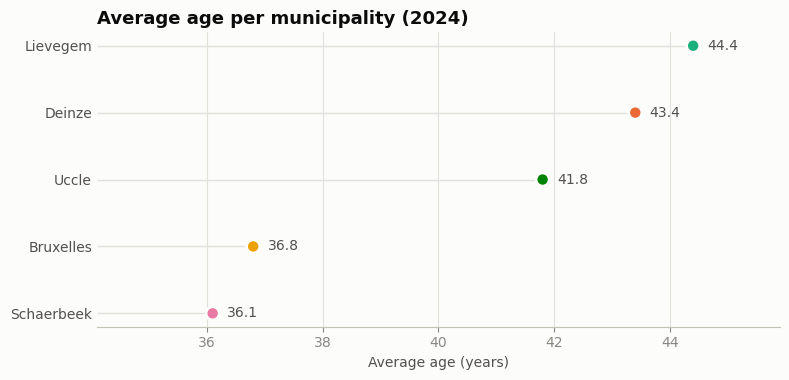

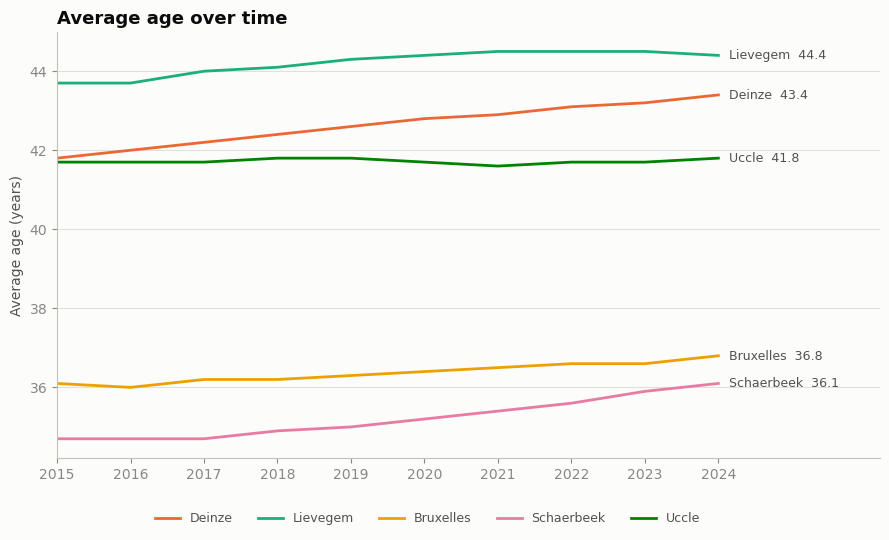

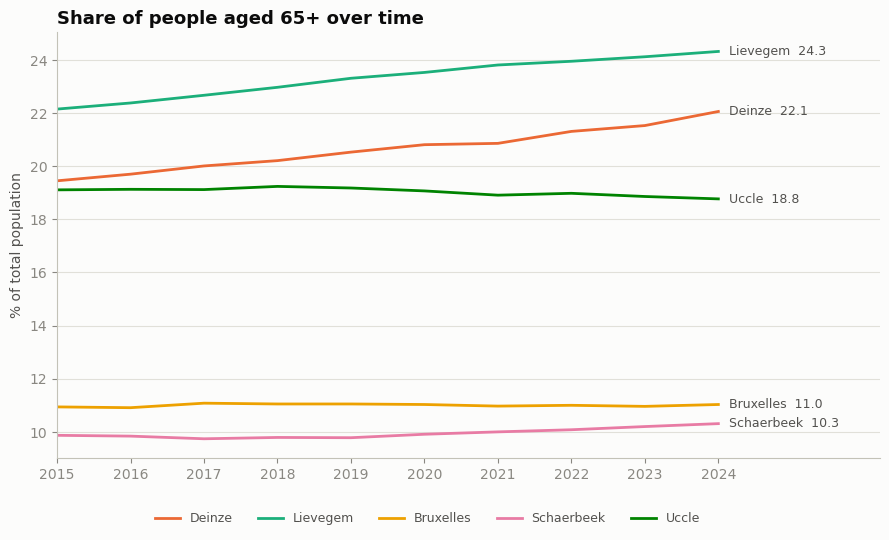

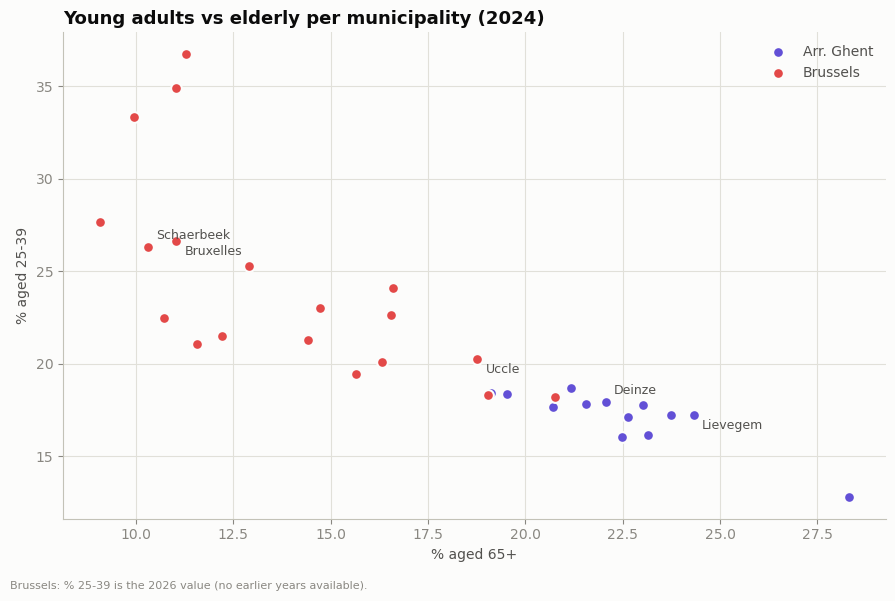

In [41]:
# --- Settings -------------------------------------------------------------
gekozen = ['Gent', 'Deinze', 'Lievegem', 'Bruxelles', 'Schaerbeek', 'Uccle']   # max 6
jaar = 2024                                                                    # year for the dot & scatter chart

# Colours (fixed order, so a municipality keeps its colour in every chart)
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
INK, INK_2, MUTED, GRID, AXIS = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'

plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'xtick.color': MUTED, 'ytick.color': MUTED, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
})

# --- One table: all municipalities (arr. Ghent + Brussels), one row per municipality and year ----
mun = to_long(age_tables['municipalities'], 'locality').assign(region='Arr. Ghent')
bru = to_long(age_tables['brussels'], 'locality').assign(region='Brussels')
alle = pd.concat([mun, bru], ignore_index=True)

kleur = {g: SERIES[i] for i, g in enumerate(gekozen)}
gevonden = [g for g in gekozen if g in set(alle['locality'])]
if len(gevonden) < len(gekozen):
    print("Not found in the age tables:", sorted(set(gekozen) - set(gevonden)))


# --- 1. Dot chart: average age per municipality --------------------------------------------
# Dots instead of bars: the axis does not start at 0, and a bar from 30 would exaggerate the differences
d = (alle[(alle['year'] == jaar) & alle['locality'].isin(gevonden)]
       .sort_values('avg_age'))
fig, ax = plt.subplots(figsize=(8, 0.5 * len(d) + 1.4))
ax.hlines(d['locality'], d['avg_age'].min() - 2, d['avg_age'], color=GRID, linewidth=1, zorder=1)
ax.scatter(d['avg_age'], d['locality'], s=90, color=[kleur[g] for g in d['locality']],
           edgecolor='#fcfcfb', linewidth=2, zorder=3)
for y, v in zip(d['locality'], d['avg_age']):
    ax.text(v + 0.25, y, f'{v:.1f}', va='center', color=INK_2)
ax.set_xlim(d['avg_age'].min() - 2, d['avg_age'].max() + 1.5)
ax.set_title(f'Average age per municipality ({jaar})')
ax.set_xlabel('Average age (years)')
ax.grid(axis='y', visible=False)
ax.set_axisbelow(True)
ax.spines['left'].set_visible(False)
ax.tick_params(axis='y', colors=INK_2, length=0)
plt.tight_layout()
plt.show()


# --- 2 & 3. Line charts over time: average age and % 65+ (one chart per measure) ------------
def lijn(maat, titel, ylabel, fmt):
    fig, ax = plt.subplots(figsize=(9, 5.5))
    eind = []
    for g in gevonden:
        s = alle[alle['locality'] == g].sort_values('year')
        s = s[s['year'].between(2015, jaar)]
        ax.plot(s['year'], s[maat], color=kleur[g], linewidth=2, label=g)
        eind.append([s[maat].iloc[-1], g])

    # Direct labels at the end of each line, pushed apart so they do not overlap
    eind.sort()
    lo, hi = ax.get_ylim()
    gap = (hi - lo) * 0.045
    posities = [eind[0][0]]
    for v, _ in eind[1:]:
        posities.append(max(v, posities[-1] + gap))
    for (v, g), y in zip(eind, posities):
        ax.text(jaar + 0.15, y, f'{g}  {v:{fmt}}', va='center', color=INK_2, fontsize=9)
    ax.set_title(titel)
    ax.set_ylabel(ylabel)
    ax.set_xlim(2015, jaar + 2.2)
    ax.set_xticks(range(2015, jaar + 1))
    ax.grid(axis='x', visible=False)
    ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.45, -0.1), ncol=len(gevonden),
              fontsize=9, labelcolor=INK_2)
    plt.tight_layout()
    plt.show()

lijn('avg_age', 'Average age over time', 'Average age (years)', '.1f')
lijn('pct_65plus', 'Share of people aged 65+ over time', '% of total population', '.1f')


# --- 4. Scatter: young adults vs elderly, all municipalities -----------------------------------
d = alle[alle['year'] == jaar]
fig, ax = plt.subplots(figsize=(9, 6))
regio_kleur = {'Arr. Ghent': SERIES[6], 'Brussels': SERIES[7]}   # slots not used by the chosen municipalities
for regio, sub in d.groupby('region'):
    ax.scatter(sub['pct_65plus'], sub['pct_25_39'], s=60, color=regio_kleur[regio],
               edgecolor='#fcfcfb', linewidth=1.5, label=regio, zorder=3)
for i, (_, r) in enumerate(d[d['locality'].isin(gevonden)].sort_values('pct_25_39').iterrows()):
    # label only the chosen municipalities; alternate above/below to limit overlap
    ax.annotate(r['locality'], (r['pct_65plus'], r['pct_25_39']), xytext=(6, 6 if i % 2 else -10),
                textcoords='offset points', color=INK_2, fontsize=9)
ax.set_title(f'Young adults vs elderly per municipality ({jaar})')
ax.set_xlabel('% aged 65+')
ax.set_ylabel('% aged 25-39')
ax.legend(frameon=False, labelcolor=INK_2)
fig.text(0.01, 0.01, 'Brussels: % 25-39 is the 2026 value (no earlier years available).',
         color=MUTED, fontsize=8)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

281,953 houses with age data and ln(affordability)


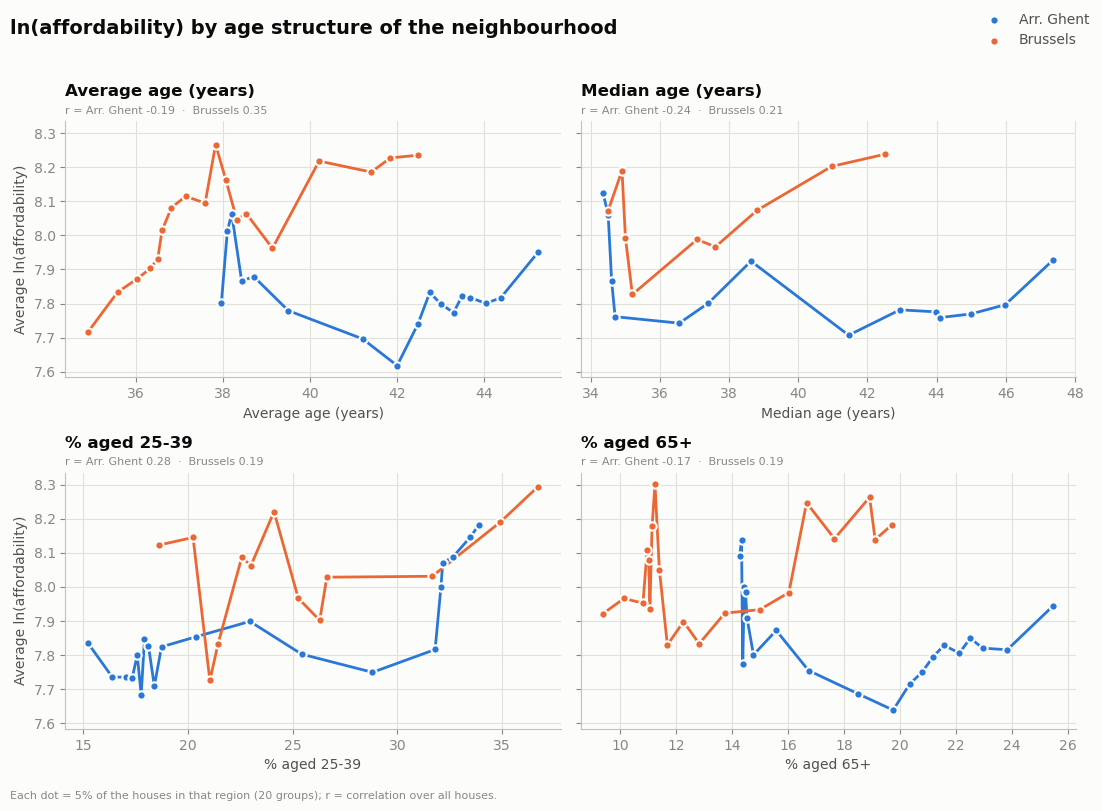

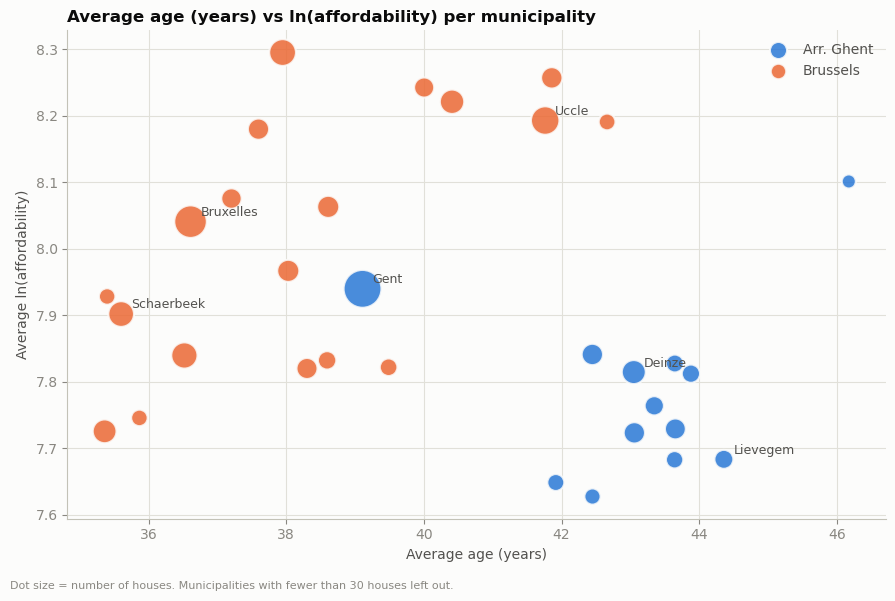

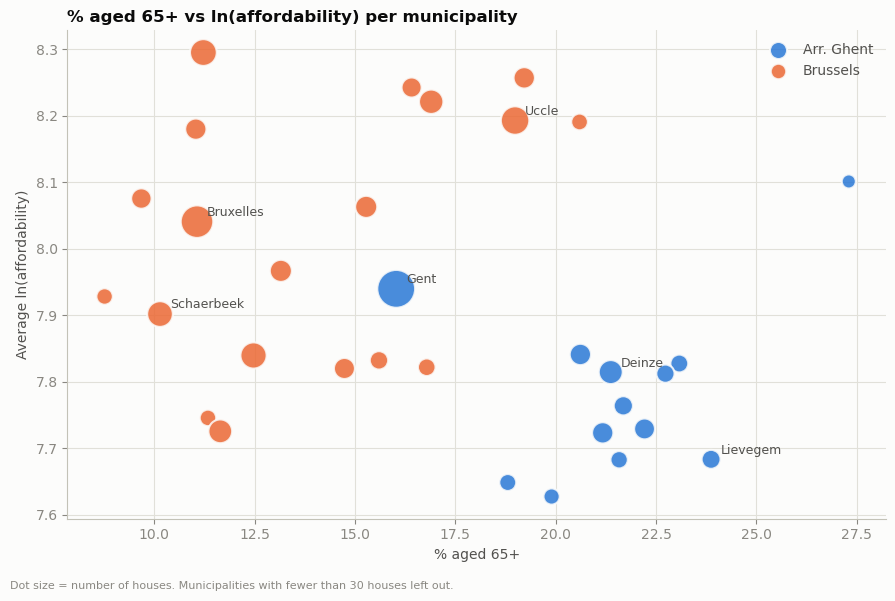


Correlation of each age measure with ln(affordability)
region               Arr. Ghent  Brussels
Average age (years)      -0.190     0.350
Median age (years)       -0.245     0.214
% aged 25-39              0.284     0.195
% aged 65+               -0.168     0.185


C:\Users\fedra\AppData\Local\Temp\ipykernel_48524\1480190618.py:95: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda s: s[list(maten)].corrwith(s[y_col]))


In [42]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# --- Settings -------------------------------------------------------------
data = data_immoweb_BG          # or data_immoweb_BG_imputed
y_col = 'ln(affordability)'
gekozen = ['Gent', 'Deinze', 'Lievegem', 'Bruxelles', 'Schaerbeek', 'Uccle']   # labelled in chart 2

SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
INK, INK_2, MUTED, GRID, AXIS = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
REGIO_KLEUR = {'Arr. Ghent': SERIES[0], 'Brussels': SERIES[1]}

plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'xtick.color': MUTED, 'ytick.color': MUTED, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
})

maten = {
    'avg_age':    'Average age (years)',
    'median_age': 'Median age (years)',
    'pct_25_39':  '% aged 25-39',
    'pct_65plus': '% aged 65+',
}

df = data.dropna(subset=list(maten) + [y_col]).copy()
df['region'] = df['admin2'].map({'Gent': 'Arr. Ghent', 'Bruxelles-Capitale': 'Brussels'})
df = df.dropna(subset=['region'])
print(f"{len(df):,} houses with age data and {y_col}")


# --- 1. Binned scatter: ln(affordability) against each age measure -------------------------
# With ~280,000 houses a normal scatter is one big blob. Instead we split each age measure
# into 20 equal-sized groups (quantiles) and plot the average ln(affordability) per group.
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True)
for ax, (maat, label) in zip(axes.flat, maten.items()):
    rs = []
    for regio, sub in df.groupby('region'):
        bins = pd.qcut(sub[maat], q=20, duplicates='drop')
        b = sub.groupby(bins, observed=True).agg(x=(maat, 'mean'), y=(y_col, 'mean'), n=(y_col, 'size'))
        ax.plot(b['x'], b['y'], color=REGIO_KLEUR[regio], linewidth=2, zorder=2)
        ax.scatter(b['x'], b['y'], s=36, color=REGIO_KLEUR[regio], edgecolor='#fcfcfb',
                   linewidth=1.5, zorder=3, label=regio)
        rs.append(f"{regio} {sub[[maat, y_col]].corr().iloc[0, 1]:.2f}")
    ax.set_title(label, pad=18)
    ax.text(0, 1.02, 'r = ' + '  ·  '.join(rs), transform=ax.transAxes, va='bottom',
            color=MUTED, fontsize=8, ha='left')
    ax.set_xlabel(label)
axes[0, 0].set_ylabel(f'Average {y_col}')
axes[1, 0].set_ylabel(f'Average {y_col}')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc='upper right', labelcolor=INK_2)
fig.suptitle(f'{y_col} by age structure of the neighbourhood', x=0.01, ha='left',
             fontsize=14, fontweight='bold', color=INK)
fig.text(0.01, 0.005, 'Each dot = 5% of the houses in that region (20 groups); r = correlation over all houses.',
         color=MUTED, fontsize=8)
plt.tight_layout(rect=(0, 0.02, 1, 0.96))
plt.show()


# --- 2. Per municipality: age measure vs average ln(affordability) -------------------------
g = (df.groupby(['region', 'locality'])
       .agg(avg_age=('avg_age', 'mean'), pct_65plus=('pct_65plus', 'mean'),
            y=(y_col, 'mean'), houses=(y_col, 'size'))
       .reset_index())
g = g[g['houses'] >= 30]          # leave out municipalities with very few houses

def per_gemeente(x, xlabel):
    fig, ax = plt.subplots(figsize=(9, 6))
    for regio, sub in g.groupby('region'):
        ax.scatter(sub[x], sub['y'], s=np.sqrt(sub['houses']) * 3, color=REGIO_KLEUR[regio],
                   alpha=0.85, edgecolor='#fcfcfb', linewidth=1.5, label=regio, zorder=3)
    for _, r in g[g['locality'].isin(gekozen)].iterrows():
        ax.annotate(r['locality'], (r[x], r['y']), xytext=(7, 4), textcoords='offset points',
                    color=INK_2, fontsize=9)
    ax.set_title(f'{xlabel} vs {y_col} per municipality')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f'Average {y_col}')
    ax.legend(frameon=False, labelcolor=INK_2, markerscale=0.6)
    fig.text(0.01, 0.01, 'Dot size = number of houses. Municipalities with fewer than 30 houses left out.',
             color=MUTED, fontsize=8)
    plt.tight_layout(rect=(0, 0.03, 1, 1))
    plt.show()

per_gemeente('avg_age', 'Average age (years)')
per_gemeente('pct_65plus', '% aged 65+')


# --- 3. Correlation table ------------------------------------------------------------------
corr = (df.groupby('region')
          .apply(lambda s: s[list(maten)].corrwith(s[y_col]))
          .round(3)
          .rename(columns=maten))
print("\nCorrelation of each age measure with", y_col)
print(corr.T.to_string())

(FEDRA) Important to note; Standard errors are dependent on the variation of a variable, because we impute variables depending on the values that are known, their variation will not increase and errors of regression will most probably be guessed to small. Possible solution -> use multiple different imputed datasets (might try later)

## 5. Regression analysis

De volgende code is gegeven door de prof en moet dus nog worden aangepast voor de juiste regressie. 

vergeet niet dat de df nu data_immoweb_BG noemt en data_immoweb_BG_imputed

In [ ]:


# ---------------------------------------------------------------------------
# 7. Running regressions
# ---------------------------------------------------------------------------

"""
In this section we estimate five regressions with 'ln(affordability)' as the
dependent variable. All regressions include admin2 and year fixed effects.
 (1) Baseline: ln(permitted new construction) and the dwelling characteristics.
 (2) As (1), plus the square of ln(permitted new construction), which allows
     the effect of new construction to depend on its level.
 (3) As (1), plus the interaction between ln(permitted new construction) and
     'housingType' (does the effect differ between houses and apartments?).
 (4) As (1), plus the interaction between ln(permitted new construction) and
     'buildYear' (does the effect differ between older and newer dwellings?).
 (5) As (1), but estimated on the non-imputed dataset ('data_immoweb_cleaned').
Regressions (1) to (4) use the imputed dataset ('data_immoweb_cleaned_imputed').
"""

# --- Prepare the data for the regressions ---

# All variables used in the regressions (including the fixed effects)
regression_vars = ["ln(affordability)", "ln(permitted_new_construction_m^2)",
                   "housingType", "isPublicSale", "estimatedArea", "hasGarden",
                   "isNewBuild", "buildYear", "heatingType",
                   "floodProneLocation", "numberOfBedrooms",
                   "numberOfBathrooms", "mScore", "greenCoverage",
                   "hasSolarPanels", "admin2", "year"]

def prepare_regression_data(df):
    """
    Prepare a dataset for the regressions.

    Parameters
    ----------
    df : DataFrame containing all variables in 'regression_vars'.

    Returns
    -------
    DataFrame with only the regression variables and without missing values,
    in which:
     - 'ln(affordability)' and 'ln(permitted_new_construction_m^2)' are renamed
       to 'ln_affordability' and 'ln_permits' (the formulas below do not accept
       brackets or '^' in variable names);
     - booleans are 1/0 and the other numeric variables regular floats (the
       formulas do not handle pandas' nullable datatypes well);
     - categories without observations are removed;
     - 'cluster' identifies the admin2-year combination of every dwelling.
    """
    # Only keep the rows without missing values: statsmodels would otherwise
    # drop them itself, but then we would not know how many were dropped
    reg_data = df[regression_vars].dropna().copy()
    reg_data = reg_data.rename(columns={
        "ln(affordability)": "ln_affordability",
        "ln(permitted_new_construction_m^2)": "ln_permits"})

    for col in ["isPublicSale", "hasGarden", "isNewBuild", "hasSolarPanels"]:
        reg_data[col] = reg_data[col].astype(int)
    for col in ["ln_affordability", "ln_permits", "estimatedArea", "mScore",
                "greenCoverage"]:
        reg_data[col] = reg_data[col].astype(float)
    reg_data["admin2"] = reg_data["admin2"].astype(str)
    for col in ["housingType", "buildYear", "heatingType", "floodProneLocation",
                "numberOfBedrooms", "numberOfBathrooms"]:
        reg_data[col] = reg_data[col].cat.remove_unused_categories()

    reg_data["cluster"] = reg_data["admin2"] + "_" + reg_data["year"].astype(str)
    return reg_data

reg_data_imputed = prepare_regression_data(data_immoweb_BG_imputed)
reg_data_not_imputed = prepare_regression_data(data_immoweb_cleaned)

print("\n" + "=" * 70)
print("NUMBER OF OBSERVATIONS USED IN THE REGRESSIONS")
print("=" * 70)
print(f"Imputed dataset:     {len(reg_data_imputed)} of {len(data_immoweb_BG_imputed)}")
print(f"Non-imputed dataset: {len(reg_data_not_imputed)} of {len(data_immoweb_cleaned)}")

# --- Write out the regression formulas ---

# The formulas follow the same logic as in R (e.g. the fixest package):
#  - 'y ~ x1 + x2' regresses y on x1 and x2 (a constant is added automatically);
#  - C(x) treats x as a categorical variable: a dummy is added for every
#    category except the first one, which is the reference category (e.g.
#    'APARTMENT' for 'housingType', '<1980' for 'buildYear');
#  - C(admin2) + C(year) add the admin2 and year fixed effects;
#  - I(x ** 2) adds the square of x (I() tells the formula to calculate x ** 2
#    instead of interpreting '**' as a formula operator);
#  - x1:x2 adds the interaction between x1 and x2 (x1 * x2 would add x1, x2
#    and x1:x2 at once).
formula_1 = ("ln_affordability ~ ln_permits"
             " + C(housingType) + isPublicSale + estimatedArea + hasGarden"
             " + isNewBuild + C(buildYear) + C(heatingType)"
             " + C(floodProneLocation) + C(numberOfBedrooms)"
             " + C(numberOfBathrooms) + mScore + greenCoverage + hasSolarPanels"
             " + C(admin2) + C(year)")

formula_2 = ("ln_affordability ~ ln_permits + I(ln_permits ** 2)"
             " + C(housingType) + isPublicSale + estimatedArea + hasGarden"
             " + isNewBuild + C(buildYear) + C(heatingType)"
             " + C(floodProneLocation) + C(numberOfBedrooms)"
             " + C(numberOfBathrooms) + mScore + greenCoverage + hasSolarPanels"
             " + C(admin2) + C(year)")

formula_3 = ("ln_affordability ~ ln_permits + ln_permits:C(housingType)"
             " + C(housingType) + isPublicSale + estimatedArea + hasGarden"
             " + isNewBuild + C(buildYear) + C(heatingType)"
             " + C(floodProneLocation) + C(numberOfBedrooms)"
             " + C(numberOfBathrooms) + mScore + greenCoverage + hasSolarPanels"
             " + C(admin2) + C(year)")

formula_4 = ("ln_affordability ~ ln_permits + ln_permits:C(buildYear)"
             " + C(housingType) + isPublicSale + estimatedArea + hasGarden"
             " + isNewBuild + C(buildYear) + C(heatingType)"
             " + C(floodProneLocation) + C(numberOfBedrooms)"
             " + C(numberOfBathrooms) + mScore + greenCoverage + hasSolarPanels"
             " + C(admin2) + C(year)")

formula_5 = formula_1  # same specification, but on the non-imputed dataset

# --- Estimate the regressions ---

# Standard errors are clustered by admin2-year combination: 'ln_permits' only
# varies at that level (all dwellings in the same arrondissement and year have
# the same value), so the observations within an admin2-year combination are
# not independent. Ordinary standard errors would then be far too small.
def fit_regression(formula, reg_data, dataset_label):
    """
    Estimate an OLS regression with standard errors clustered by admin2-year.

    Parameters
    ----------
    formula : str, the regression formula.
    reg_data : DataFrame prepared with prepare_regression_data().
    dataset_label : str, the name of the dataset, shown in the results table.

    Returns
    -------
    The regression results.
    """
    results = smf.ols(formula, data=reg_data).fit(
        cov_type="cluster",
        cov_kwds={"groups": pd.factorize(reg_data["cluster"])[0]})
    # Store the name of the dataset, so that it can be shown in the table
    results.dataset_label = dataset_label
    return results

results_1 = fit_regression(formula_1, reg_data_imputed, "Imputed")
results_2 = fit_regression(formula_2, reg_data_imputed, "Imputed")
results_3 = fit_regression(formula_3, reg_data_imputed, "Imputed")
results_4 = fit_regression(formula_4, reg_data_imputed, "Imputed")
results_5 = fit_regression(formula_5, reg_data_not_imputed, "Not imputed")

all_results = [results_1, results_2, results_3, results_4, results_5]

# --- Present the results in one table ---

# Order of the variables in the table: first the variables related to new
# construction, then the controls, then the constant. The fixed effects are
# left out of the table (drop_omitted=True drops every variable that is not in
# this list); instead, the rows below the table show that they are included.
all_variables = list(dict.fromkeys(name for results in all_results
                                   for name in results.params.index))
fixed_effects = [name for name in all_variables
                 if name.startswith(("C(admin2)", "C(year)"))]
permit_variables = [name for name in all_variables if "ln_permits" in name]
controls = [name for name in all_variables
            if name not in fixed_effects + permit_variables + ["Intercept"]]
regressor_order = permit_variables + controls + ["Intercept"]

# Extra rows at the bottom of the table (statsmodels 0.15 or later):
#  - fixed_effects adds a row per fixed effect ('admin2 FE', 'year FE'), which
#    shows "Yes" if the regression contains that fixed effect;
#  - info_dict adds our own rows. Each entry is a function that receives the
#    results of one regression and returns the text to show for it.
results_table = summary_col(
    all_results,
    model_names=["(1)", "(2)", "(3)", "(4)", "(5)"],
    stars=True,
    float_format="%0.3f",
    regressor_order=regressor_order,
    drop_omitted=True,
    fixed_effects=["admin2", "year"],
    fe_absent="No",
    info_dict={
        "Dataset": lambda x: x.dataset_label,
        "SE clustered by": lambda x: "admin2-year",
        "N": lambda x: f"{int(x.nobs):,}",
    })

# summary_col sorts the extra rows alphabetically; put them in a logical order
info_rows = ["admin2 FE", "year FE", "Dataset", "SE clustered by", "N"]
table = results_table.tables[0]
results_table.tables[0] = pd.concat([table[~table.index.isin(info_rows)],
                                     table.loc[info_rows]])

print("\n" + "=" * 70)
print("REGRESSION RESULTS (dependent variable: ln(affordability))")
print("=" * 70)
print(results_table)

NameError: name 'data_immoweb_cleaned_imputed' is not defined